# Visualize Last-Layer Diagnostics Across Context Lengths

This Visualize notebook loads the cached data produced by `Generate-last-layer-diagnostics-across-context-lengths.ipynb` and generates the final-layer comparison of graph-spectral diagnostics across context lengths for the main numerical input families using Llama-3.2-3B, as presented under **Robustness and Layerwise Consistency of Graph-Spectral Diagnostics** in the appendix. Shaded bands show standard deviations across realizations.


In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.transforms import Bbox
from matplotlib.ticker import FormatStrFormatter


In [2]:
DATA_PATH = Path("cache") / "all_diagnostics_last_layer_vs_context_length.npz"

# Load cached plotting data
with np.load(DATA_PATH, allow_pickle=False) as data:
    # Labels, context lengths, and cache metadata
    input_names = data["input_names"].astype(str)
    context_token_counts = data["context_token_counts"].astype(int)
    run_ids = data["run_ids"].astype(int)
    num_layers = int(data["num_layers"].item())
    num_ensemble_runs = int(data["num_ensemble_runs"].item())
    model_name = str(data["model_name"].item())
    diagnostic_layer_mode = (
        str(data["diagnostic_layer_mode"].item())
        if "diagnostic_layer_mode" in data.files
        else str(data["metric_layer_mode"].item())
        if "metric_layer_mode" in data.files
        else "last_layer"
    )
    last_layer_attention_layer_index = (
        int(data["last_layer_attention_layer_index"].item())
        if "last_layer_attention_layer_index" in data.files
        else -1
    )
    last_layer_signal_layer_index = (
        int(data["last_layer_signal_layer_index"].item())
        if "last_layer_signal_layer_index" in data.files
        else -2
    )
    last_layer_resolved_attention_layer_index = (
        int(data["last_layer_resolved_attention_layer_index"].item())
        if "last_layer_resolved_attention_layer_index" in data.files
        else num_layers - 1
    )
    last_layer_resolved_signal_layer_index = (
        int(data["last_layer_resolved_signal_layer_index"].item())
        if "last_layer_resolved_signal_layer_index" in data.files
        else num_layers - 1
    )

    # Means and standard deviations across realizations
    active_modes_mean = data["active_modes_mean"].astype(float)
    active_modes_std = data["active_modes_std"].astype(float)

    fiedler_mean = data["fiedler_mean"].astype(float)
    fiedler_std = data["fiedler_std"].astype(float)

    hfer_mean = data["hfer_mean"].astype(float)
    hfer_std = data["hfer_std"].astype(float)

if diagnostic_layer_mode != "last_layer":
    raise ValueError(f"Expected a last-layer cache, got diagnostic_layer_mode={diagnostic_layer_mode!r}.")


In [3]:
def _diagnostic_line_style(data_name):
    # Use consistent styles across diagnostics
    if data_name in {"Constant 500", "Constant sampled"}:
        style = dict(color="#D8D7E6", linestyle="-", marker="o", linewidth=2.0)
    elif data_name == "Logistic r=3.2":
        style = dict(color="#C6D9F1", linestyle="-", marker="o", linewidth=2.0)
    elif data_name == "Logistic r=3.5":
        style = dict(color="#A9C8EA", linestyle="-", marker="o", linewidth=2.0)
    elif data_name == "Logistic r=3.55":
        style = dict(color="#83B2DC", linestyle="-", marker="o", linewidth=2.0)
    elif data_name == "Logistic r=3.566":
        style = dict(color="#5F98CA", linestyle="-", marker="o", linewidth=2.0)
    elif data_name == "Logistic r=3.5692":
        style = dict(color="#3E78B2", linestyle="-", marker="o", linewidth=2.2)
    elif data_name == "Logistic r=3.5698":
        style = dict(color="#24518A", linestyle="-", marker="o", linewidth=2.2)
    elif data_name == "Logistic r=3.9":
        style = dict(color="#E68169", linestyle="-.", marker="o", linewidth=2.4)
    elif data_name == "Logistic r=4.0":
        style = dict(color="#C8525E", linestyle="-.", marker="o", linewidth=2.4)
    elif data_name == "Lorenz":
        style = dict(color="#98334F", linestyle="-.", marker="o", linewidth=2.8)
    else:
        style = dict(color="#4C72B0", linestyle="-", marker="o", linewidth=2.0)

    # Draw chaotic and Lorenz curves above periodic curves
    if data_name == "Lorenz":
        style["zorder"] = 5
    elif data_name in {"Logistic r=3.9", "Logistic r=4.0"}:
        style["zorder"] = 4
    else:
        style["zorder"] = 2

    style["markersize"] = 4.0
    return style


Saved figures/last_layer_combined_diagnostics.pdf


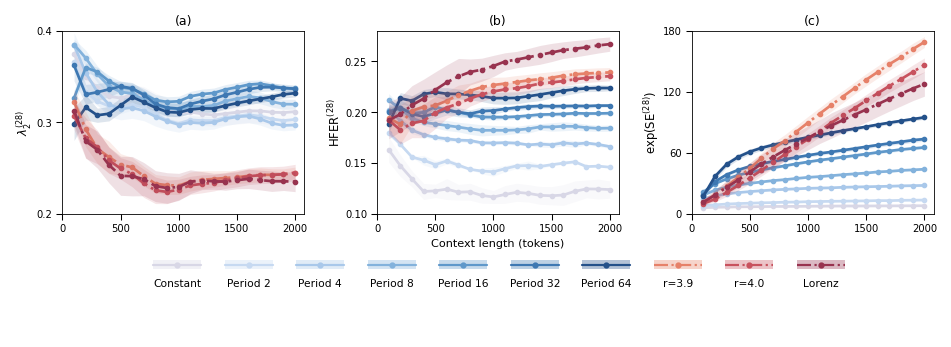

In [4]:
FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(exist_ok=True)
COMBINED_FIGURE_PATH = FIGURE_DIR / "last_layer_combined_diagnostics.pdf"

x = context_token_counts.astype(float)


def _plot_context_diagnostic(ax, mean, std):
    for input_idx, data_name in enumerate(input_names):
        y = mean[input_idx].astype(float)
        band = std[input_idx].astype(float)
        style = _diagnostic_line_style(str(data_name))
        zorder = style.get("zorder", 2)
        ax.plot(
            x,
            y,
            color=style["color"],
            linestyle=style["linestyle"],
            linewidth=1.3,
            marker=style["marker"],
            markersize=1.7,
            zorder=zorder,
        )
        ax.fill_between(
            x,
            y - band,
            y + band,
            color=style["color"],
            alpha=0.15,
            linewidth=0,
            zorder=max(zorder - 0.5, 0),
        )


def _format_combined_axis(ax, ylabel):
    ax.set_ylabel(ylabel, labelpad=1, fontsize=5.6)
    ax.set_xlim(0, 2080)
    ax.set_xticks([0, 500, 1000, 1500, 2000])
    ax.set_axisbelow(True)
    ax.grid(False)
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)


complexity_legend_order = [
    "Constant sampled",
    "Logistic r=3.2",
    "Logistic r=3.5",
    "Logistic r=3.55",
    "Logistic r=3.566",
    "Logistic r=3.5692",
    "Logistic r=3.5698",
    "Logistic r=3.9",
    "Logistic r=4.0",
    "Lorenz",
]


def _complexity_legend_rows(data_name):
    label_map = {
        "Constant sampled": ("Constant", ""),
        "Logistic r=3.2": ("Period 2", ""),
        "Logistic r=3.5": ("Period 4", ""),
        "Logistic r=3.55": ("Period 8", ""),
        "Logistic r=3.566": ("Period 16", ""),
        "Logistic r=3.5692": ("Period 32", ""),
        "Logistic r=3.5698": ("Period 64", ""),
        "Logistic r=3.9": ("r=3.9", ""),
        "Logistic r=4.0": ("r=4.0", ""),
        "Lorenz": ("Lorenz", ""),
    }
    return label_map.get(str(data_name), (str(data_name), ""))


def _add_complexity_strip_legend(fig):
    ordered_names = [name for name in complexity_legend_order if name in set(input_names.astype(str))]
    ax_leg = fig.add_axes([0.075, 0.130, 0.910, 0.185])
    ax_leg.set_xlim(-0.55, len(ordered_names) - 0.45)
    ax_leg.set_ylim(0.0, 1.0)
    ax_leg.axis("off")

    spacing_scale = 0.84
    swatch_half_width = 0.28
    swatch_height = 0.115
    legend_center = 0.5 * (len(ordered_names) - 1)

    def _legend_x(raw_x):
        return legend_center + spacing_scale * (float(raw_x) - legend_center)

    for idx, data_name in enumerate(ordered_names):
        legend_x = _legend_x(idx)
        style = _diagnostic_line_style(str(data_name))
        ax_leg.add_patch(
            Rectangle(
                (legend_x - swatch_half_width, 0.7850),
                2.0 * swatch_half_width,
                swatch_height,
                facecolor=style["color"],
                edgecolor="none",
                alpha=0.34,
            )
        )
        ax_leg.plot(
            [legend_x - swatch_half_width, legend_x + swatch_half_width],
            [0.8425, 0.8425],
            color=style["color"],
            linestyle=style["linestyle"],
            linewidth=1.05,
            solid_capstyle="round",
        )
        ax_leg.plot(legend_x, 0.8425, marker=style["marker"], markersize=2.0, color=style["color"])
        top_label, bottom_label = _complexity_legend_rows(data_name)
        ax_leg.text(legend_x, 0.605, top_label, ha="center", va="center", fontsize=5.082)
        if bottom_label:
            ax_leg.text(legend_x, 0.505, bottom_label, ha="center", va="center", fontsize=5.082)

with plt.rc_context({
    "font.size": 7.6,
    "axes.labelsize": 5.4,
    "axes.titlesize": 6.0,
    "xtick.labelsize": 4.8,
    "ytick.labelsize": 4.8,
    "legend.fontsize": 8.778,
    "axes.linewidth": 0.4,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
}):
    fig = plt.figure(figsize=(6.30, 2.87), dpi=150)
    gs = fig.add_gridspec(
        1,
        3,
        left=0.068,
        right=0.990,
        top=0.830,
        bottom=0.405,
        wspace=0.30,
    )

    ax_fiedler = fig.add_subplot(gs[0, 0])
    ax_hfer = fig.add_subplot(gs[0, 1])
    ax_active = fig.add_subplot(gs[0, 2])

    _plot_context_diagnostic(ax_fiedler, fiedler_mean, fiedler_std)
    _plot_context_diagnostic(ax_hfer, hfer_mean, hfer_std)
    _plot_context_diagnostic(ax_active, active_modes_mean, active_modes_std)

    _format_combined_axis(ax_fiedler, r"$\lambda_2^{(28)}$")
    _format_combined_axis(ax_hfer, r"$\mathrm{HFER}^{(28)}$")
    _format_combined_axis(ax_active, r"$\exp(\mathrm{SE}^{(28)})$")

    ax_fiedler.set_ylim(0.20, 0.40)
    ax_fiedler.set_yticks([0.20, 0.30, 0.40])
    ax_fiedler.yaxis.set_major_formatter(FormatStrFormatter("%.1f"))
    ax_hfer.set_ylim(0.10, 0.28)
    ax_hfer.set_yticks([0.10, 0.15, 0.20, 0.25])
    ax_hfer.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
    ax_active.set_ylim(0.0, 180.0)
    ax_active.set_yticks([0, 60, 120, 180])
    for ax in (ax_fiedler, ax_hfer, ax_active):
        ax.tick_params(axis="both", which="major", length=2.8, pad=2.0)
    for panel_label, ax in zip(["(a)", "(b)", "(c)"], [ax_fiedler, ax_hfer, ax_active]):
        ax.set_title(panel_label, pad=3.0)

    _add_complexity_strip_legend(fig)
    middle_axis_center = ax_hfer.get_position().x0 + 0.5 * ax_hfer.get_position().width
    fig.supxlabel("Context length (tokens)", x=middle_axis_center, y=0.325, fontsize=5.4)
    fig.align_ylabels([ax_fiedler, ax_hfer, ax_active])
    fig.canvas.draw()
    tight_bbox = fig.get_tightbbox(fig.canvas.get_renderer()).padded(0.02)
    pdf_bbox = Bbox.from_extents(
        tight_bbox.x0,
        tight_bbox.y0 + 0.30,
        tight_bbox.x1,
        tight_bbox.y1,
    )
    fig.savefig(COMBINED_FIGURE_PATH, format="pdf", bbox_inches=pdf_bbox)
    print(f"Saved {COMBINED_FIGURE_PATH}")
    plt.show()
